<a href="https://colab.research.google.com/github/JuanFerMC/Labs-Model-and-Sim-Sist/blob/main/lab4_parte2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 4 - Parte 2. Regularización de modelos.

## Objetivo general

En este laboratorio el estudiante analizará el fenómeno del **sobreajuste** (*overfitting*) en modelos de aprendizaje automático, aprenderá a detectarlo mediante la comparación entre error de entrenamiento y error de prueba, y aplicará tres técnicas de regularización para mitigarlo:

1. **Parada anticipada** (*early stopping*): detener el entrenamiento antes de que el modelo memorice el conjunto de entrenamiento.
2. **Regularización L2** (*weight decay*): penalizar los pesos grandes en la función de pérdida para reducir la complejidad efectiva del modelo.
3. **Efecto del tamaño del conjunto de entrenamiento**: analizar como la cantidad de datos disponibles influye sobre el sobreajuste.

El laboratorio está organizado en cinco ejercicios:

| Ejercicio | Modelo | Tarea principal |
|-----------|--------|-----------------|
| 1 | MLP y regresión logística | Implementar `diff_train_test` para detectar sobreajuste |
| 2 | MLP | Regularizar con parada anticipada y analizar su efecto |
| 3 | MLP | Regularizar con L2 y analizar su efecto según el número de neuronas |
| 4 | regresión logística | Regularizar con L2 y comparar con el MLP |
| 5 | MLP | Analizar el efecto del tamaño del conjunto de entrenamiento |

---

## Fundamento teórico: sobreajuste y regularización

### Sobreajuste

el **sobreajuste** ocurre cuando un modelo aprende los datos de entrenamiento con demasiado detalle, incluyendo el ruido, y pierde capacidad de generalizar a datos nuevos. Se manifiesta como:

- Error de entrenamiento muy bajo.
- Error de prueba considerablemente más alto.

La diferencia entre ambos errores es el indicador principal de sobreajuste. Un buen modelo minimiza está brecha.

### Causas principales del sobreajuste

- **Modelo demasiado complejo** para la cantidad de datos disponibles (muchas capas, muchas neuronas, muchos pesos).
- **Conjunto de entrenamiento pequeño**: el modelo no tiene suficientes ejemplos para aprender la distribución real de los datos.
- **Falta de regularización**: no se impone ninguna restricción sobre los pesos del modelo.

### técnicas de regularización

**Parada anticipada (early stopping):** durante el entrenamiento, se reserva una fraccion de los datos de entrenamiento como conjunto de validación interna. Si el error en ese conjunto deja de mejorar durante un número determinado de épocas (`n_iter_no_change`), el entrenamiento se detiene. Esto evita que el modelo continue ajustandose al ruido del conjunto de entrenamiento.

**Regularización L2:** se agrega un término de penalización a la función de pérdida proporcional a la suma de los cuadrados de todos los pesos: `perdida_total = perdida_original + alpha * sum(w^2)`. el parámetro `alpha` controla la intensidad de la regularización. Pesos grandes son penalizados, lo que induce soluciones más simples y generalizables. En `sklearn`, el parámetro correspondiente es `alpha` para el MLP y `C` para la regresión logística (donde `C = 1 / lambda`, es decir, valores bajos de `C` corresponden a mayor regularización).

---

## Configuración del entorno

Las siguientes celdas descargan las dependencias e inicializan la sesion. Se deben ejecutar en orden antes de comenzar los ejercicios.

> **Nota:** La celda de login solicitara las credenciales institucionales del estudiante.

In [8]:
!wget -nc --no-cache -O init.py -q https://raw.githubusercontent.com/jdariasl/Intro_ML_2025/master/init.py
import init; init.init(force_download=False); init.get_weblink()

In [16]:
from local.lib.rlxmoocapi import submit, session
import inspect
session.LoginSequence(endpoint=init.endpoint, course_id=init.course_id, lab_id="L04.02", varname="student");

logging in as juanf.mona@udea.edu.co... please wait

-------------
using course session introml::udea.vir.20262.g2
success!! you are logged in
-------------


In [10]:
#configuración del laboratorio
from Labs.commons.utils.lab4 import *
_ = part_2()
import seaborn as sns

En este laboratorio vamos analizar el efecto del sobreajuste (*over-fitting*), como identificarlo y como podemos regualizar los modelos para evitarlo o disminuir su efecto.

En este laboratorio, vamos a enfocarnos en 2 modelos (usando la librería de sklearn):

1. Regresión logística
2. MLP

El sobreajuste también puede ser causado por la **maldición de la dimensionalidad**. **No vamos enfocarnos en como tratar esta condición** ya que esto lo vamos a ver un poco más adelante cuando evaluemos las técnicas de selección de características.

## Conjunto de datos: vino (Wine)

Se usa el dataset **Wine** de `sklearn` ([documentación](https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-recognition-dataset)), que contiene 178 muestras de vinos italianos caracterizadas por 13 atributos químicos. Originalmente es un problema de clasificación con 3 clases.

Para este laboratorio, el problema se convierte a **clasificación binaria**: la clase 0 se mantiene y las clases 1 y 2 se fusionan en una sola clase (clase 1). Esto simplifica el problema y permite trabajar con regresión logística binaria.

**Simulación de conjunto de entrenamiento pequeño:** se usa `train_test_split` con `test_size=0.6` para simular la condicion de pocos datos de entrenamiento (solo el 40% del total). Este es un escenario artificial para forzar el sobreajuste y observar el efecto de las técnicas de regularización.



Vamos usar la base de datos [iris](https://archive.ics.uci.edu/ml/datasets/iris) para realizar nuestra práctica. Vamos a convertir el problema a un problema de clasificación biclase

> **esta celda no debe modificarse.**

In [11]:
x,y = load_wine(return_X_y=True)
unique, counts  = np.unique(y, return_counts=True)
print("distribución original (claves de las etiquetas, valores de número de muestras): \n", dict(zip(unique, counts )))
y = np.where(y==0, 0, 1)
unique, counts  = np.unique(y, return_counts=True)
print("distribución luego de conversión (claves de las etiquetas, valores de número de muestras): \n", dict(zip(unique, counts )))

distribución original (claves de las etiquetas, valores de número de muestras): 
 {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}
distribución luego de conversión (claves de las etiquetas, valores de número de muestras): 
 {np.int64(0): np.int64(59), np.int64(1): np.int64(119)}


Una de las condiciones para que se presente sobreajuste es tener un conjunto de entrenamiento pequeño.

En nuestra práctica vamos a simular esta condición para ver que técnicas podemos usar para reducir el efecto del sobreajuste.

**Nota**
1. En un problema real, si se observa que las medidas de rendimiento no satisfacen las necesidades, la respuesta puede ser que se necesiten más datos en el conjunto de entrenamiento. Las condiciones que usaremos en está práctica son para ver el efecto del sobre ajuste.


In [12]:
# simular conjunto de datos pequeño
x, x_test, y, y_test = train_test_split(x, y, test_size=0.6, random_state=10, stratify = y)
scaler = StandardScaler().fit(x)
x = scaler.transform(x)
x_test = scaler.transform(x_test)

In [41]:
def restore_wine_dataset():
    global x, x_test, y, y_test
    x, y = load_wine(return_X_y=True)
    y = np.where(y==0, 0, 1)
    x, x_test, y, y_test = train_test_split(x, y, test_size=0.6, random_state=10, stratify=y)
    scaler = StandardScaler().fit(x)
    x = scaler.transform(x)
    x_test = scaler.transform(x_test)
    print("Dataset de Wine restaurado correctamente (13 características).")

restore_wine_dataset()

Dataset de Wine restaurado correctamente (13 características).


## Ejercicio 1 - Detectar sobre ajuste

### Concepto

Para detectar sobreajuste se comparan el **error de entrenamiento** y el **error de prueba**. Si un modelo tiene error de entrenamiento muy bajo pero error de prueba alto, está memorizando los datos de entrenamiento en lugar de aprender la distribución subyacente.

La metrica usada en este laboratorio es el **error de clasificación**, definido como `1 - accuracy_score(y_real, y_pred)`.

- Un error de entrenamiento de 0.05 y de prueba de 0.40 indica sobreajuste severo (diferencia de 0.35).
- Un error de entrenamiento de 0.12 y de prueba de 0.14 indica un modelo bien regularizado (diferencia de 0.02).

### Implementación: función `diff_train_test`


La función recibe un modelo ya entrenado (`sklearnModel`) y los conjuntos de datos. Se deben completar tres asignaciones:

1. **`error_train`**: predecir sobre `Xtrain` usando `sklearnModel.predict(Xtrain)` y calcular `1 - accuracy_score(Ytrain, predicciones_train)`.

2. **`error_test`**: predecir sobre `Xtest` usando `sklearnModel.predict(Xtest)` y calcular `1 - accuracy_score(Ytest, predicciones_test)`.

3. **`diff`**: calcular la diferencia absoluta entre `error_train` y `error_test` usando `abs(error_train - error_test)`. el valor absoluto garantiza que el resultado sea siempre positivo, independientemente de cual error sea mayor.

> **Importante:** el modelo ya está entrenado cuando llega a esta función. No se debe llamar a `fit` dentro de `diff_train_test`.

En nuestro primer ejercicio vamos a crear una función para detectar las diferencias entre los errores de entrenamiento y de prueba.
1. Calcular error de entrenamiento y prueba
2. La función recibe de manera arbitraria un estimador de sklearn
3. [usar accuracy score como medida de rendimiento](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html#sklearn.metrics.accuracy_score)
4. Se debe retornar la diferencia absoluta (solo números positivos) entre entrenamiento y prueba.

In [98]:
from sklearn.metrics import accuracy_score
import numpy as np

def diff_train_test(Xtrain, Ytrain, Xtest, Ytest, sklearnModel):
    """función que retorna error de entrenamiento
    Xtrain: matriz numpy con las muestras de entrenamiento
    Ytrain: matrix numpy con las etiquetas de entrenamiento
    Xtest: matriz numpy con las muestras de prueba
    Ytest: matrix numpy con las etiquetas de prueba
    sklearnModel: objeto estimador de sklearn ya entrenado

    retorna: tupla con tres elementos:
        error entrenamiento, error test y
        diff absoluta entre error y test
    """
    # 1. Obtener las predicciones
    pred_train = sklearnModel.predict(Xtrain)
    pred_test = sklearnModel.predict(Xtest)

    # 2. Calcular el error (1.0 - exactitud)
    error_train = 1.0 - accuracy_score(Ytrain, pred_train)
    error_test = 1.0 - accuracy_score(Ytest, pred_test)

    # 3. Calcular la diferencia absoluta
    diff = abs(error_train - error_test)

    return (error_train, error_test, diff)

**Registra tu solución en línea**

In [90]:
# Aseguramos que las variables globales tengan el dataset de Wine para que T1 valide con éxito
restore_wine_dataset()

Dataset de Wine restaurado correctamente (13 características).


In [93]:
student.submit_task(namespace=globals(), task_id='T1');

### Verificación: sobreajuste en MLP y regresión logística

Las siguientes dos celdas verifican el nivel de sobreajuste en los dos modelos base (sin regularización o con regularización minima). el estudiante debe observar la diferencia entre error de entrenamiento y error de prueba en cada caso y relacionarla con la complejidad de cada modelo:

- el MLP tiene `hidden_layer_sizes=[20,20]`, lo que le da considerable capacidad para ajustarse a los datos de entrenamiento.
- La regresión logística con `penalty=None` no aplica ninguna regularización, lo que puede llevar a sobreajuste cuando el modelo tiene muchos grados de libertad respecto al número de muestras.

Con la función construida, vamos a usarla para verificar la differencia entre el error de entrenamiento y prueba para los dos modelos que vamos a usar:
1. MLP con dos capas, cada una con 64 neuornas. `random_state=1` es usado para lograr tener los mismos resultados siempre
2. [Regresión logística forzada para que no use ninguna regularización](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression). `random_state=1` es usado para lograr tener los mismos resultados

In [94]:
mlp = MLPClassifier(hidden_layer_sizes=[20,20], max_iter=500, alpha =1e-6, random_state=1)
mlp.fit(x, y)
# Corregimos la cadena eliminando la 'f' inicial para que .format() reciba correctamente los valores desempaquetados
print("MLP entrenamiento:{0:.3f}, test:{1:.3f} y diff {2:.3f}".format(*diff_train_test(x,y, x_test, y_test,mlp)))

MLP entrenamiento:1.000, test:1.000 y diff 0.000


In [95]:
reg = LogisticRegression(penalty=None, max_iter=500,  random_state=1)
reg.fit(x, y)
print("Logistic Regresion entrenamiento:{0:.3f}, test:{1:.3f} y diff {2:.3f}".format(*diff_train_test(x,y, x_test, y_test, reg)))

Logistic Regresion entrenamiento:1.000, test:0.981 y diff 0.019


## Ejercicio 2 - Experimentar con MLP regularizado

### Concepto: parada anticipada

La **parada anticipada** es una técnica de regularización que monitorea el error en un subconjunto de validación durante el entrenamiento. cuando el error de validación deja de mejorar durante `n_iter_no_change` épocas consecutivas, el entrenamiento se interrumpe y se restauran los pesos del mejor estado observado.

esta técnica es equivalente a buscar el punto óptimo en la curva de complejidad del modelo: antes de ese punto el modelo tiene subajuste, despues tiene sobreajuste.

En `sklearn`, la parada anticipada se activa con el parámetro `early_stopping=True` en `MLPClassifier`. el parámetro `validation_fraction` (por defecto 0.1) controla que fraccion de los datos de entrenamiento se usa internamente como conjunto de validación para monitorear el entrenamiento.


Vamos a comenzar a regularizar el modelo, el primer método que usaremos es el de parada anticipada (*early-stopping*). Este ya se encuentra implementado dentro de la libreria, vamos a experimentar con este parámetro y el número de neuronas en el MLP.

In [ ]:
#@title Pregunta Abierta
#@markdown ¿Explique en sus palabras a que corresponde el metodo de parada anticipada?
respuesta = "" #@param {type:"string"}

In [ ]:
#@title Pregunta Abierta
#@markdown ¿Basandose en la documentación de sklearn para MLPClassifier que relación tiene el parametro validation_fraction con la parada anticipada?
respuesta = "" #@param {type:"string"}

### Implementación: función `exp_mlp_early_stop`

Se deben completar los siguientes fragmentos dentro del bucle:

1. **Instanciar `MLPClassifier`** completando los parámetros faltantes en `MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, max_iter=1000, ...)`:
   - `early_stopping=early_stop`: activa o desactiva la parada anticipada según el valor del bucle externo.
   - `random_state=1`: semilla para reproducibilidad.

2. **Entrenar el modelo**: `mlp.fit(Xtrain, Ytrain)`.

3. **Llamar a `diff_train_test`**: `error_train, error_test, diff = diff_train_test(Xtrain, Ytrain, Xtest, Ytest, mlp)`. esta función ya está implementada en el ejercicio anterior y retorna los tres valores que se necesitan.

4. **Asignar los resultados al DataFrame**: completar `resultados.loc[idx, 'error de entrenamiento'] = error_train`, y de forma análoga para `error_test` y `diff`.

> **Nota:** `hidden_layer_sizes = tuple(2*[neurons])` crea una arquitectura de 2 capas ocultas, cada una con `neurons` neuronas. esta expresión es equivalente a `(neurons, neurons)` pero permite variar el número de neuronas dinamicamente.

In [75]:
# ejercicio de código
def exp_mlp_early_stop(num_neurons, is_early_stop, Xtrain,Xtest,Ytrain, Ytest):
    """ función para realizar experimentos con el MLP y early stopping
    num_neurons: list de enteros con el número de neuronas a usar
    is_early_stop: list de boolean para confirmar si se aplica early stop
    Xtrain: matriz de numpy con las muestras de entrenamiento
    Xtest: matriz de numpy con las muestras de prueba
    ytrain: vector numpy con las etiquetas de entrenamiento
    ytest: vector numpy con las etiquetas de prueba

    Retorna: dataframe con 5 columnas:
        - número de neuronas
        - error de entrenamiento
        - error de prueba
        - diferencia entrenamiento y prueba
        - flag early stopping
    """
    resultados = pd.DataFrame()
    idx = 0
    for early_stop in is_early_stop:
        for neurons in num_neurons:
            #Haga el llamado a la función para crear y entrenar el modelo usando los datos de entrenamiento
            # prestar atención a los parametros, correctos.
            hidden_layer_sizes = tuple(2*[neurons])
            # llame el parametro para que el MLP pare anticipadamente
            # Ajuste la semilla en 1 para garantizar la reproducibilidad de los resultados
            mlp = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, max_iter=1000, early_stopping=early_stop, random_state=1)
            # entrenar
            mlp.fit(Xtrain, Ytrain)
            # llamar a la funcion creada anteriomente
            error_train, error_test, diff = diff_train_test(Xtrain, Ytrain, Xtest, Ytest, mlp)

            resultados.loc[idx,'neuronas en capas ocultas'] = neurons
            resultados.loc[idx,'error de entrenamiento'] = error_train
            resultados.loc[idx,'error de prueba'] = error_test
            resultados.loc[idx,'diferencia entrenamiento y prueba'] = diff
            resultados.loc[idx,'is_early_stop'] = early_stop
            idx+=1
    return (resultados)

In [49]:
# Nos aseguramos de tener cargado el dataset correcto antes del experimento 2
restore_wine_dataset()

Dataset de Wine restaurado correctamente (13 características).


**Registra tu solución en línea**

In [50]:
student.submit_task(namespace=globals(), task_id='T2');

### Experimentos y visualización

La gráfica muestra la diferencia entre error de entrenamiento y error de prueba en función del número de neuronas, comparando modelos con y sin parada anticipada. el estudiante debe observar:
- Si la parada anticipada reduce la brecha entre errores (indicador de menos sobreajuste).
- Si el efecto es consistente para todas las arquitecturas evaluadas.
- En que rango de número de neuronas el sobreajuste es más pronunciado.

In [76]:
res_early_stop = exp_mlp_early_stop( [4,8,16], [True, False], x, x_test, y, y_test)

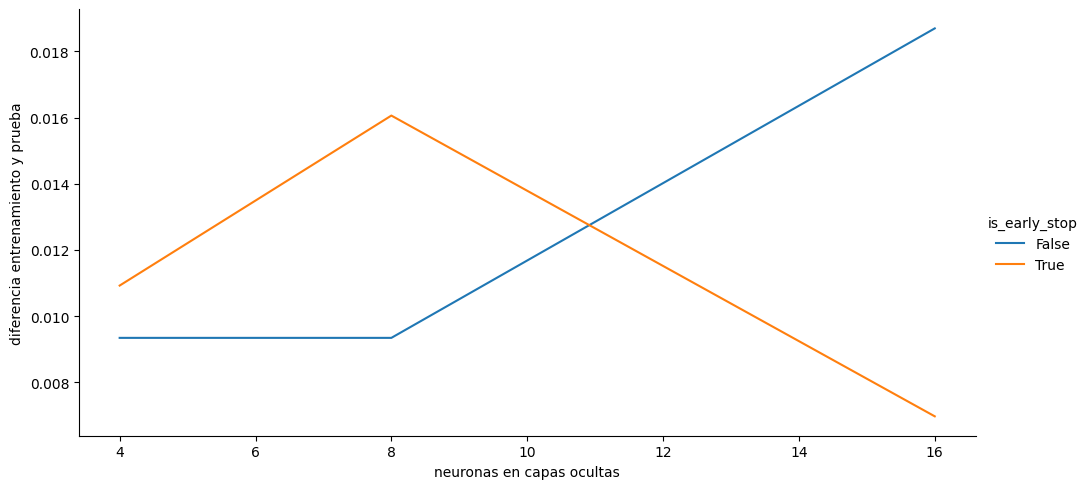

In [77]:
sns.relplot(x = 'neuronas en capas ocultas', y='diferencia entrenamiento y prueba', hue = 'is_early_stop', data = res_early_stop, kind = 'line', aspect=2)
plt.show()

## Ejercicio 3: Regularización L2

### Concepto: regularización L2

La **Regularización L2** (también llamada *weight decay* o regularización de Tikhonov) agrega un término de penalización a la función de pérdida:

`perdida_total = perdida_original + alpha * ||w||^2`

donde `||w||^2` es la norma euclidiana al cuadrado de todos los pesos del modelo. el efecto de este término es desincentivar pesos grandes: el optimizador equilibra entre ajustarse bien a los datos (minimizar la pérdida original) y mantener pesos pequeños (minimizar la penalización).

**Efectos de `alpha`:**
- `alpha` pequeño (cercano a 0): poca regularización, el modelo puede sobreajustar.
- `alpha` grande: fuerte regularización, el modelo puede subajustar (los pesos se restringen tanto que el modelo no puede ajustarse a los datos).

En `sklearn`, el parámetro `alpha` del `MLPClassifier` controla directamente la intensidad de la regularización L2.


In [ ]:
#@title Pregunta Abierta
#@markdown ¿Explique en sus palabras en qué consiste la regularización L2?
respuesta = "" #@param {type:"string"}

### Implementación: función `exp_mlp_l2`

Se deben completar los fragmentos dentro del bucle:

1. **Instanciar `MLPClassifier`** completando los parámetros faltantes en `MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, max_iter=1000, ...)`:
   - `alpha=l2`: valor de regularización L2 del bucle externo.
   - `random_state=1`: semilla para reproducibilidad.

2. **Entrenar el modelo**: llamar al método `fit` sobre `mlp` con los datos de entrenamiento.

3. **Llamar a `diff_train_test`** para obtener los tres errores.

4. **Asignar los resultados al DataFrame**: completar las tres asignaciones de error de entrenamiento, error de prueba y diferencia.

> **distinción importante:** en el Ejercicio 2 se uso `early_stopping` (un mecanismo basado en el criterio de parada). En este ejercicio se usa `alpha` (un término de penalización sobre los pesos). Ambas son técnicas de regularización validas pero operan de forma completamente diferente. el estudiante debe asegurarse de usar el parámetro correcto según el ejercicio.

In [78]:
# ejercicio de código
def exp_mlp_l2(num_neurons, l2_values, Xtrain,Xtest,Ytrain, Ytest):
    """ función para realizar experimentos con el MLP con regularización L2

    num_neurons: list de enteros con el numero de neuronas a usar
    l2: list de floats con valores para regularizacion l2
    Xtrain: matriz de numpy con las muestras de entrenamiento
    Xtest: matriz de numpy con las muestras de prueba
    ytrain: vector numpy con las etiquetas de entrenamiento
    ytest: vector numpy con las etiquetas de prueba

    Retorna: dataframe con 5 columnas:
        - número de neuronas
        - error de entrenamiento
        - error de prueba
        - diferencia entrenamiento y prueba
        - valor de l2
    """

    resultados = pd.DataFrame()
    idx = 0
    for l2 in l2_values:
        for neurons in num_neurons:
            #Haga el llamado a la función para crear y entrenar el modelo usando los datos de entrenamiento
            # prestar atención a los parametros, correctos.
            hidden_layer_sizes = tuple(2*[neurons])
            # llame el parametro adecuado del MLPClassifier
            # Ajuste la semilla en 1 para garantizar la reproducibilidad de los resultados
            mlp = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, max_iter=1000, alpha=l2, random_state=1)
            mlp.fit(Xtrain, Ytrain)
            # llamar la funcion creada anteriomente
            error_train, error_test, diff = diff_train_test(Xtrain, Ytrain, Xtest, Ytest, mlp)
            resultados.loc[idx,'neuronas en capas ocultas'] = neurons
            resultados.loc[idx,'error de entrenamiento'] = error_train
            resultados.loc[idx,'error de prueba'] = error_test
            resultados.loc[idx,'diferencia entrenamiento y prueba'] = diff
            resultados.loc[idx,'l2'] = l2
            idx+=1
    return (resultados)

In [79]:
# Nos aseguramos de tener cargado el dataset correcto antes del experimento 3
restore_wine_dataset()

Dataset de Wine restaurado correctamente (13 características).


**Registra tu solución en línea**

In [56]:
student.submit_task(namespace=globals(), task_id='T3');

### Experimentos y visualización

La gráfica muestra la diferencia entre error de entrenamiento y prueba en función del valor de `alpha`, separada por número de neuronas. el estudiante debe observar:
- Si existe un valor óptimo de `alpha` que minimiza la brecha entre errores.
- Si arquitecturas con más neuronas requieren mayor regularización para controlar el sobreajuste.
- Qué ocurre cuando `alpha` es muy grande (subajuste).

In [80]:
res_l2 = exp_mlp_l2([4,16,64], [1e-3,1e-1,1e0, 1e1, 2e2, 1e3], x, x_test, y, y_test)

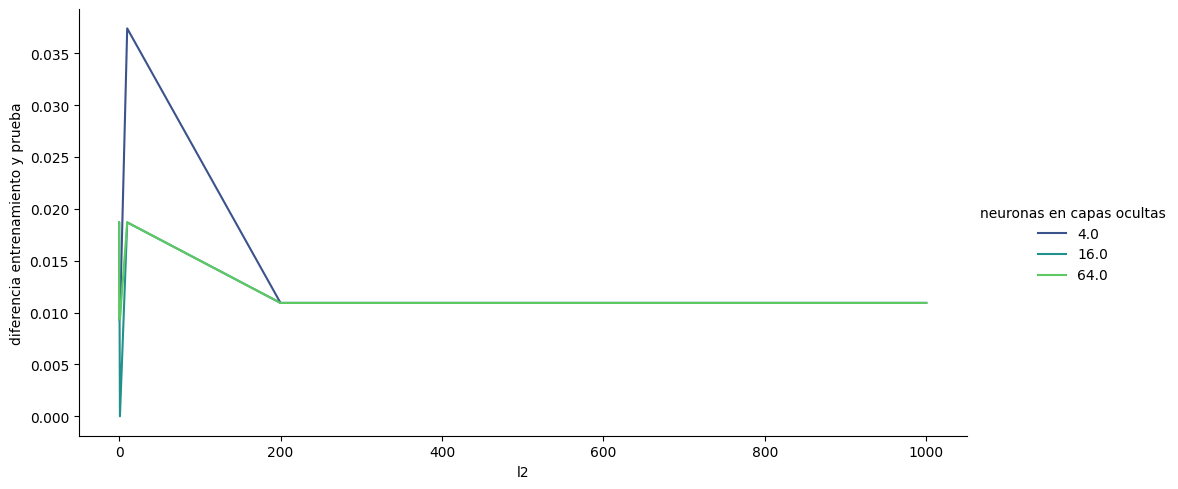

In [81]:
sns.relplot(x = 'l2', y='diferencia entrenamiento y prueba',
            hue = 'neuronas en capas ocultas',
            data = res_l2, kind = 'line',
            aspect=2, palette=sns.color_palette('viridis', n_colors=res_l2['neuronas en capas ocultas'].nunique()))
plt.show()

## Ejercicio 4 - Experimentar con regresión logística regularizada

Ahora vamos explorar la opciones de regularización de la regresión logística. En la libreria se implementan más formás de regularizar, pero solo vamos a comprobar la regularización de norma L2.

### Concepto: regularización L2 en regresión logística

La regresión logística es un modelo lineal que puede sobreajustar cuando tiene muchos parámetros respecto al número de muestras. En `sklearn`, la regularización L2 se controla mediante el parámetro `C`:

`C = 1 / lambda`

donde `lambda` es el coeficiente de regularización equivalente al `alpha` del MLP. Por lo tanto:
- **`C` grande** (por ejemplo, 1000): poca regularización (equivalente a `alpha` pequeño).
- **`C` pequeño** (por ejemplo, 0.001): fuerte regularización (equivalente a `alpha` grande).

esta convención es inversa a la del MLP, lo que puede ser una fuente de confusion. el estudiante debe tener esto presente al interpretar los resultados.


### Implementación: función `exp_reg_l2`


Se deben completar los fragmentos dentro del bucle:

1. **Instanciar `LogisticRegression`** completando los parámetros faltantes en `LogisticRegression(max_iter=500, ...)`:
   - `C=l2`: valor del parámetro de regularización del bucle. Aunque la variable se llama `l2`, se pasa directamente al parámetro `C` de la regresión logística.
   - `random_state=1`: semilla para reproducibilidad.

2. **Llamar a `diff_train_test`** para obtener los tres errores usando el modelo ya entrenado.

3. **Asignar los resultados al DataFrame**: completar las cuatro asignaciones (valor de l2, error de entrenamiento, error de prueba y diferencia).

> **Recordatorio:** en `LogisticRegression`, el parámetro de regularización es `C` (no `alpha`). A diferencia del MLP, un valor alto de `C` corresponde a poca regularización.

In [99]:
def exp_reg_l2(l2_values, Xtrain, Xtest, Ytrain, Ytest):
    """ función para realizar experimentos con el LR con regularización L2

    l2_values: list de floats con valores para regularizacion l2
    Xtrain: matriz de numpy con las muestras de entrada
    Xtest: matriz de numpy con las muestras de prueba
    Ytrain: vector numpy con las etiquetas de las muestras de entrenamiento
    Ytest: vector numpy con las etiquetas de las muestras de prueba

    Retorna: dataframe con 4 columnas:
        - Valor del parámetro de regularización
        - error de entrenamiento
        - error de prueba
        - diferencia entre error de entrenamiento y prueba
    """
    resultados = pd.DataFrame()
    idx = 0
    for l2 in l2_values:
        # C es el inverso de la intensidad de regularización l2
        reg = LogisticRegression(penalty='l2', max_iter=500, C=1.0/l2, random_state=1)
        reg.fit(Xtrain, Ytrain)

        # Calcular los errores con la función creada anteriormente
        error_train, error_test, diff = diff_train_test(Xtrain, Ytrain, Xtest, Ytest, reg)

        resultados.loc[idx, 'l2'] = l2
        resultados.loc[idx, 'error de entrenamiento'] = error_train
        resultados.loc[idx, 'error de prueba'] = error_test
        resultados.loc[idx, 'diferencia entrenamiento y prueba'] = diff

        idx += 1
    return resultados

**Registra tu solución en línea**

In [100]:
# Aseguramos que las variables globales tengan el dataset de Wine para que T4 valide con éxito
restore_wine_dataset()

Dataset de Wine restaurado correctamente (13 características).


In [103]:
student.submit_task(namespace=globals(), task_id='T4');

### Experimentos y visualización

La gráfica muestra la diferencia entre error de entrenamiento y prueba en función del valor de `C` (en escala logaritmica). el estudiante debe comparar este comportamiento con el observado para el MLP en el Ejercicio 3, prestando atención a:
- En que sentido opera el parámetro `C` respecto al sobreajuste (a diferencia del `alpha` del MLP).
- Si la regresión logística es más o menos sensible al sobreajuste que el MLP en este conjunto de datos.

In [101]:
reg_l2 = exp_reg_l2([1e-6,1e-3,1e-1,1e0, 1e1], x, x_test, y, y_test)

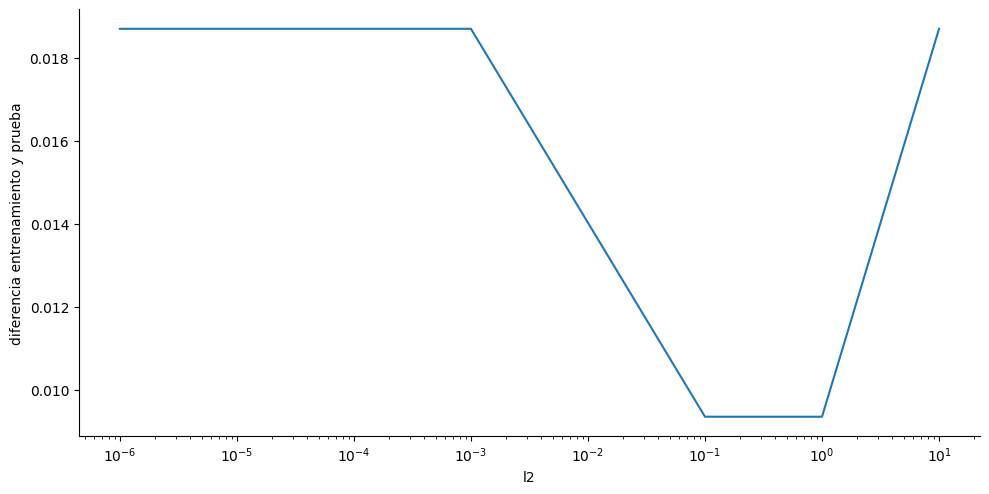

In [102]:
g = sns.relplot(x = 'l2', y='diferencia entrenamiento y prueba',
               data = reg_l2, kind = 'line',
                aspect=2)

g.set(xscale="log")
plt.show()

In [ ]:
#@title Pregunta Abierta
#@markdown ¿Qué efecto tiene el parametro que controla L2 en la regresión logistica en relación con el sobreajuste? ¿Es diferente al MLP?
respuesta= "" #@param {type:"string"}

## Ejercicio 5 Efecto del tamaño del conjunto de entrenamiento

Finalmente como mencionamos anteriormente, en los ejercicios que hemos resuelto estábamos simulando la situación de un conjunto de datos de entrenamiento pequeño. En nuestro último ejercicio vamos a comprobar el efecto del tamaño del conjunto de entrenamiento.

### Concepto: tamaño del conjunto de entrenamiento y sobreajuste

Una causa fundamental del sobreajuste es la **desproporción entre la complejidad del modelo y la cantidad de datos disponibles**. Un modelo muy complejo entrenado con pocos datos aprende el ruido específico de esas muestras, en lugar de los patrones generales de la distribución.

Al aumentar el número de muestras de entrenamiento:
- el modelo tiene más información para aprender la distribución real.
- el error de entrenamiento tiende a subir ligeramente (el modelo no puede memorizar todos los datos).
- el error de prueba tiende a bajar (el modelo generaliza mejor).
- La brecha entre ambos errores se reduce.

Este comportamiento se resume en las **curvas de aprendizaje** (*learning curves*), que grafican el error de entrenamiento y el de prueba en función del número de muestras de entrenamiento.

### Implementación: función `train_size_experiments`

Se deben completar los siguientes fragmentos dentro del bucle:

1. **Completar `train_test_split`**: agregar el parámetro `train_size=train_pct` a la llamada existente. Este parámetro indica la proporción de muestras que van al conjunto de entrenamiento (por ejemplo, `0.3` significa 30% para entrenamiento y 70% para prueba).

2. **Entrenar el modelo**: `sk_estimator.fit(X=Xtrain, y=Ytrain)`.

3. **Llamar a `diff_train_test`**: `error_train, error_test, diff = diff_train_test(Xtrain, Ytrain, Xtest, Ytest, sk_estimator)`.

4. **Asignar los resultados al DataFrame**:
   - `error de entrenamiento = error_train`
   - `error de prueba = error_test`
   - `diferencia entrenamiento y prueba = diff`
   - `tamaño de entrenamiento = train_pct`: el valor del porcentaje de entrenamiento actual.

> **Nota sobre la normalización:** el scaler se ajusta sobre `Xtrain` y luego se aplica a `Xtest`. está linea ya está implementada y no debe modificarse. Es un ejemplo de correcta separacion entre entrenamiento y prueba: el conjunto de prueba nunca influye en la normalización.

In [28]:
# ejercicio de codigo
def train_size_experiments(train_pcts,X,Y,sk_estimator):
    """función que realiza experimentos para
        comprobar la influencia del tamaño del conjunto
        de entrenamiento.

    train_pcts: lista de floats con los % de entrenamiento a evaluar
    X: matriz de numpy con el conjunto de muestras
    Y: vector numpy con las etiquetas de salida correspondientes
    sk_estimator: estimador/modelo de sklearn definido (sin entrenar)

    Retorna: dataframe con 4 columnas:
        - tamaño del conjunto de entrenamiento
        - error de entrenamiento
        - error de prueba
        - diferencia entrenamiento y prueba
    """
    resultados = pd.DataFrame()
    idx = 0
    for train_pct in train_pcts:
        #complete con el parámetro train_pct (recuerde que son proporciones)
        Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, stratify = Y, random_state=10, train_size=train_pct)
        # normalizamos
        scaler = StandardScaler().fit(Xtrain)
        Xtrain = scaler.transform(Xtrain)
        Xtest = scaler.transform(Xtest)
        # entrenar!
        sk_estimator.fit(X=Xtrain, y=Ytrain)
        # llamar la funcion creada anteriomente
        error_train, error_test, diff = diff_train_test(Xtrain, Ytrain, Xtest, Ytest, sk_estimator)
        resultados.loc[idx,'error de entrenamiento'] = error_train
        resultados.loc[idx,'error de prueba'] = error_test
        resultados.loc[idx,'diferencia entrenamiento y prueba'] = diff
        # complete con el tamaño del entrenamiento
        resultados.loc[idx,'tamaño de entrenamiento'] = train_pct
        idx+=1

    return (resultados)

**Registra tu solución en línea**

In [32]:
student.submit_task(namespace=globals(), task_id='T5');

### Experimento: efecto del tamaño del conjunto de entrenamiento

Se cambia el dataset a **Iris** (150 muestras) para tener un rango más amplio de proporciónes de entrenamiento. El problema se convierte a binario fusionando la clase 2 en la clase 1.

Se evalúan proporciones de entrenamiento de `[0.2, 0.3, 0.5, 0.7, 0.9]`. El estudiante debe observar en la grafica:
- Cómo cambia el error de entrenamiento al aumentar el tamaño del conjunto de entrenamiento.
- Cómo cambia el error de prueba al aumentar el tamaño del conjunto de entrenamiento.
- En que proporción la brecha entre ambos errores es minima.

> Esta gráfica es una versión manual de la **curva de aprendizaje**. `sklearn` tiene una función integrada ([`learning_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html)) que realiza este análisis de forma automática y con validación cruzada.

In [29]:
x,y = load_iris(return_X_y=True)
unique, counts  = np.unique(y, return_counts=True)
print("distribución original (claves las etiquetas, valores el número de muestras): \n", dict(zip(unique, counts )))
y = np.where(y==2, 0, 1)
unique, counts  = np.unique(y, return_counts=True)
print("distribución luego de conversión (claves las etiquetas, valores el número de muestras): \n", dict(zip(unique, counts )))

distribución original (claves las etiquetas, valores el número de muestras): 
 {np.int64(0): np.int64(50), np.int64(1): np.int64(50), np.int64(2): np.int64(50)}
distribución luego de conversión (claves las etiquetas, valores el número de muestras): 
 {np.int64(0): np.int64(50), np.int64(1): np.int64(100)}


In [30]:
# comprobamos con un MLP
mlp = MLPClassifier(hidden_layer_sizes=[64,64], max_iter=1000, random_state=1)
train_size_exp = train_size_experiments([0.2,0.3,0.5,0.7,0.9], x, y, mlp)

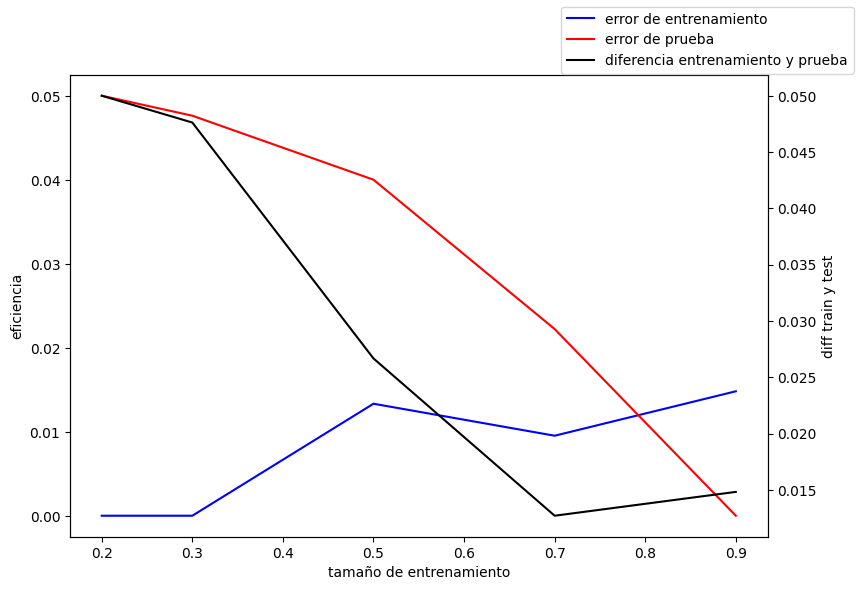

In [31]:
# vemos las tres medidas
ax = train_size_exp.plot(x="tamaño de entrenamiento", y="error de entrenamiento", color="b", legend=False, figsize = (9,6))
train_size_exp.plot(x="tamaño de entrenamiento", y="error de prueba",  ax=ax, legend=False, color="r")
ax2 = ax.twinx()
ax2.set_ylabel("diff train y test")
ax.set_ylabel("eficiencia")
train_size_exp.plot(x="tamaño de entrenamiento", y="diferencia entrenamiento y prueba", ax=ax2, legend=False, color="k")
ax.figure.legend()
plt.show()

**Notas Finales**

Para tener en cuenta: [Sklearn tiene una función que realiza algo similar a lo que creamos en el anterior ejercicio y que usamos en la clase sobre complejidad de modelos.](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html)

Debemos notar que en está práctica exageramos algunas situaciones para lograr medir y ver el efecto del sobreajuste. En un problema fuera de la didáctica del laboratorio un flujo de trabajo ideal es el siguiente:

<img src="https://scikit-learn.org/stable/_images/grid_search_workflow.png" alt="grid_search_workflow" width="500"/>


1. Dividimos el conjunto al inicio, reservando un conjunto de test.
2. Verificamos los mejores parámetros mediante validación cruzada.
3. Reentrenamos con los mejores parámetros y realizamos la evaluación final. (Esto se puede hacer usando GridSearch)
4. En está última etapa es donde validamos si existe sobre ajuste. Si existe, se deben incluir parámetros para mitigar el sobre ajuste en la validación cruzada y volver al paso 2.
5. La curva de aprendizaje puede ser necesaria si no logramos mitigar el sobre ajuste, como una forma de evaluar y tener evidencias sobre la deficiencia del tamaño del conjunto de muestras con el que estamos trabajando.